In [3]:
# ==============================================================================
# Step 1: Load and Inspect Credit Card Fraud Detection Dataset (CCFD)
# ==============================================================================

import pandas as pd
import numpy as np
import kagglehub

# --- Download the CCFD dataset via kagglehub ---
print("Downloading CCFD dataset...")
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print(f"Path to dataset files: {path}")

# Load the CSV file
csv_path = f"{path}/creditcard.csv"
df = pd.read_csv(csv_path)

# --- Basic Inspections ---
print(f"\nDataset Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print("\nData Types & Null Counts:")
print(df.info())

# Class distribution
fraud_counts = df['Class'].value_counts()
fraud_ratio = df['Class'].mean() * 100
print(f"\nClass Distribution:\n{fraud_counts}")
print(f"Fraud Percentage: {fraud_ratio:.4f}%")

# Display first few rows
df.head()


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud

Dataset Shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data Types & Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# ==============================================================================
# Step 2: Stratified Data Split and Feature Scaling
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch

# --- 1. Separate Features and Target ---
feature_cols = [c for c in df.columns if c != 'Class']
X = df[feature_cols].values
y = df['Class'].values

print(f"Total features count: {len(feature_cols)}")

# --- 2. Stratified Chronological/Random Partition (70% Train, 15% Val, 15% Test) ---
# First split: 70% Train, 30% Temp (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Second split: Temp into 50% Val and 50% Test (each 15% of total)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# --- 3. Feature Scaling via StandardScaler ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled   = scaler.transform(X_val).astype(np.float32)
X_test_scaled  = scaler.transform(X_test).astype(np.float32)

y_train = y_train.astype(np.float32)
y_val   = y_val.astype(np.float32)
y_test  = y_test.astype(np.float32)

print("\nPartition Summary:")
print(f"Train set : {X_train_scaled.shape} | Fraud count: {int(y_train.sum())} ({y_train.mean()*100:.3f}%)")
print(f"Val set   : {X_val_scaled.shape}   | Fraud count: {int(y_val.sum())}   ({y_val.mean()*100:.3f}%)")
print(f"Test set  : {X_test_scaled.shape}  | Fraud count: {int(y_test.sum())}  ({y_test.mean()*100:.3f}%)")


Total features count: 30

Partition Summary:
Train set : (199364, 30) | Fraud count: 344 (0.173%)
Val set   : (42721, 30)   | Fraud count: 74   (0.173%)
Test set  : (42722, 30)  | Fraud count: 74  (0.173%)


In [5]:
# ==============================================================================
# Step 3: Define FT-Transformer Architecture (PyTorch)
# ==============================================================================

import torch
import torch.nn as nn

class FeatureTokenizer(nn.Module):
    """
    Projects each numerical feature into a vector of size d_model.
    Input shape: (batch_size, num_features)
    Output shape: (batch_size, num_features, d_model)
    """
    def __init__(self, num_features, d_model):
        super().__init__()
        # Each feature gets its own learnable weight and bias (Linear projection)
        self.feature_weights = nn.Parameter(torch.randn(num_features, d_model))
        self.feature_biases = nn.Parameter(torch.randn(num_features, d_model))

    def forward(self, x):
        # x: (batch_size, num_features)
        # Expand x to (batch_size, num_features, 1) to apply projection
        x = x.unsqueeze(-1)
        return x * self.feature_weights + self.feature_biases

class FTTransformer(nn.Module):
    def __init__(self, num_features, d_model=32, nhead=4, num_layers=3, dropout=0.2):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_model)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Classification head: Pool the features (mean) and project to 1
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        # 1. Tokenize: (B, N) -> (B, N, D)
        x = self.tokenizer(x)

        # 2. Transformer: (B, N, D) -> (B, N, D)
        x = self.transformer(x)

        # 3. Global Pooling: Mean over the features dimension
        x = x.transpose(1, 2) # (B, D, N)
        x = self.pool(x).squeeze(-1) # (B, D)

        # 4. Classification
        return self.classifier(x)

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = FTTransformer(num_features=30, d_model=32, nhead=4, num_layers=3).to(device)

print(f"Model initialized on {device}")
print(model)


Model initialized on cuda
FTTransformer(
  (tokenizer): FeatureTokenizer()
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=128, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (classifier): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [6]:
# ==============================================================================
# Complete Self-contained Pipeline: FT-Transformer on CCFD (Google Colab / GPU)
# ==============================================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

# --- 1. Set Device & Random Seed ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
print(f"Executing on device: {device}")

# --- 2. Load and Prepare Dataset ---
# Update path if needed (e.g., 'creditcard.csv' or kaggle path)
try:
    df = pd.read_csv('/kaggle/input/creditcardfraud/creditcard.csv')
except:
    df = pd.read_csv('creditcard.csv')

X = df.drop(columns=['Class']).values
y = df['Class'].values

# Stratified Split: 70% Train, 15% Val, 15% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

num_features = X_train_scaled.shape[1]

# --- 3. FT-Transformer Architecture ---
class FeatureTokenizer(nn.Module):
    """
    Projects each numerical feature into an embedding vector of size d_model.
    """
    def __init__(self, num_features, d_model):
        super().__init__()
        self.feature_weights = nn.Parameter(torch.randn(num_features, d_model))
        self.feature_biases = nn.Parameter(torch.randn(num_features, d_model))

    def forward(self, x):
        # x: (batch_size, num_features, 1)
        x = x.unsqueeze(-1)
        return x * self.feature_weights + self.feature_biases

class FTTransformer(nn.Module):
    def __init__(self, num_features, d_model=32, nhead=4, num_layers=3, dropout=0.2):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        # 1. Tokenize: (B, N) -> (B, N, D)
        x = self.tokenizer(x)
        # 2. Transformer layers
        x = self.transformer(x)
        # 3. Global feature pooling
        x = x.transpose(1, 2)
        x = self.pool(x).squeeze(-1)
        # 4. Binary logit output
        return self.classifier(x)

# Initialize Model
model = FTTransformer(num_features=num_features, d_model=32, nhead=4, num_layers=3).to(device)

# --- 4. DataLoaders ---
batch_size = 1024
tr_ds = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                      torch.tensor(y_train, dtype=torch.float32))
v_ds  = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32),
                      torch.tensor(y_val, dtype=torch.float32))

tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True)
v_loader  = DataLoader(v_ds, batch_size=batch_size, shuffle=False)

# --- 5. Loss & Optimizer ---
pos_weight_val = (len(y_train) - y_train.sum()) / y_train.sum()
pos_weight = torch.tensor([pos_weight_val], device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

# --- 6. Training & Validation Loop ---
print("\n================ Training FT-Transformer ================")
best_val_prauc = 0.0

for epoch in range(1, 11):
    model.train()
    running_loss = 0.0
    for Xb, yb in tr_loader:
        Xb, yb = Xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(Xb).squeeze(-1)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(yb)

    # Validation evaluation
    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for Xb, yb in v_loader:
            Xb = Xb.to(device)
            probs = torch.sigmoid(model(Xb).squeeze(-1)).cpu().numpy()
            val_preds.extend(probs)
            val_targets.extend(yb.numpy())

    val_prauc = average_precision_score(val_targets, val_preds)
    avg_loss = running_loss / len(tr_ds)
    print(f"Epoch {epoch:02d}/10 | Train Loss: {avg_loss:.4f} | Val PR-AUC: {val_prauc:.4f}")

    if val_prauc > best_val_prauc:
        best_val_prauc = val_prauc
        torch.save(model.state_dict(), "best_ft_transformer.pt")

print(f"\nTraining Complete. Best Validation PR-AUC: {best_val_prauc:.4f}")


Executing on device: cuda

================ Training FT-Transformer ================
Epoch 01/10 | Train Loss: 0.5373 | Val PR-AUC: 0.6636
Epoch 02/10 | Train Loss: 0.3423 | Val PR-AUC: 0.6256
Epoch 03/10 | Train Loss: 0.3057 | Val PR-AUC: 0.6542
Epoch 04/10 | Train Loss: 0.2723 | Val PR-AUC: 0.6742
Epoch 05/10 | Train Loss: 0.2482 | Val PR-AUC: 0.6444
Epoch 06/10 | Train Loss: 0.2366 | Val PR-AUC: 0.6325
Epoch 07/10 | Train Loss: 0.2373 | Val PR-AUC: 0.6352
Epoch 08/10 | Train Loss: 0.2261 | Val PR-AUC: 0.6399
Epoch 09/10 | Train Loss: 0.2026 | Val PR-AUC: 0.6540
Epoch 10/10 | Train Loss: 0.2128 | Val PR-AUC: 0.6644

Training Complete. Best Validation PR-AUC: 0.6742


In [7]:
# ==============================================================================
# Step 5: Evaluate FT-Transformer on Test Set
# ==============================================================================

import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# --- 1. Prepare Test DataLoader ---
ts_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)
ts_loader = DataLoader(ts_ds, batch_size=1024, shuffle=False)

# --- 2. Load Best Model Weights ---
model.load_state_dict(torch.load("best_ft_transformer.pt"))
model.eval()

# --- 3. Run Inference ---
test_preds = []
test_targets = []

with torch.no_grad():
    for Xb, yb in ts_loader:
        Xb = Xb.to(device)
        probs = torch.sigmoid(model(Xb).squeeze(-1)).cpu().numpy()
        test_preds.extend(probs)
        test_targets.extend(yb.numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)

# --- 4. Calculate Evaluation Metrics ---
test_prauc = average_precision_score(test_targets, test_preds)
test_rocauc = roc_auc_score(test_targets, test_preds)

print("\n================ FT-Transformer Test Set Results ================")
print(f"Test PR-AUC  : {test_prauc:.4f}")
print(f"Test ROC-AUC : {test_rocauc:.4f}")

# Binary predictions using 0.5 threshold
preds_binary = (test_preds >= 0.5).astype(int)

print("\nClassification Report (Threshold = 0.5):")
print(classification_report(test_targets, preds_binary, digits=4))

print("Confusion Matrix:")
print(confusion_matrix(test_targets, preds_binary))



================ FT-Transformer Test Set Results ================
Test PR-AUC  : 0.7483
Test ROC-AUC : 0.9726

Classification Report (Threshold = 0.5):
              precision    recall  f1-score   support

         0.0     0.9998    0.9799    0.9897     42648
         1.0     0.0696    0.8649    0.1288        74

    accuracy                         0.9797     42722
   macro avg     0.5347    0.9224    0.5593     42722
weighted avg     0.9981    0.9797    0.9883     42722

Confusion Matrix:
[[41792   856]
 [   10    64]]


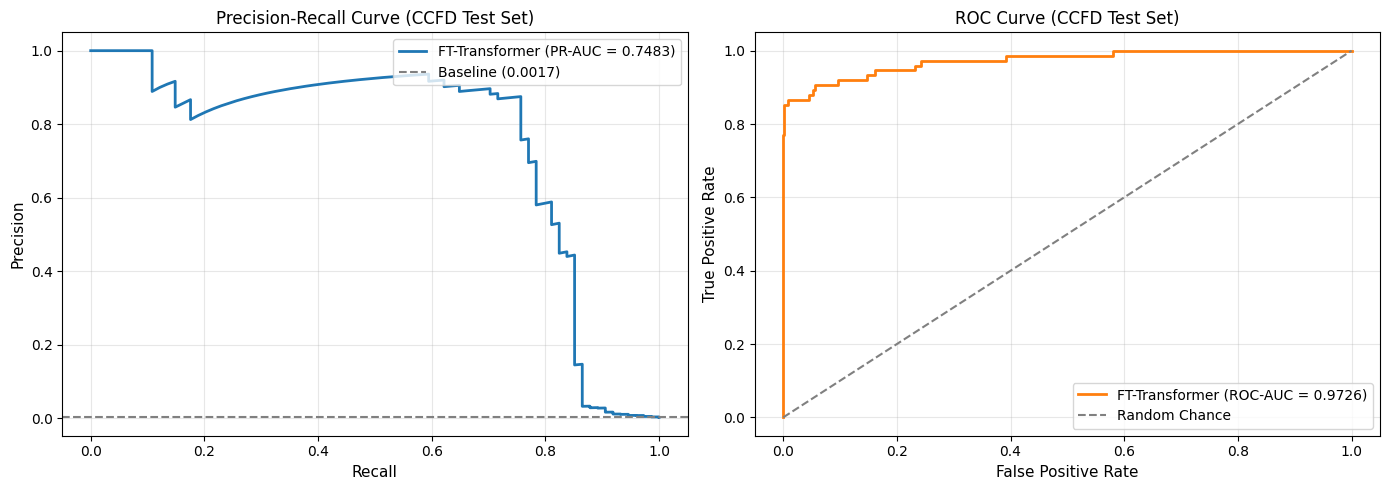

In [8]:
# ==============================================================================
# Step 6: Plot PR Curve and ROC Curve
# ==============================================================================

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

# --- 1. Compute Curves ---
precision, recall, _ = precision_recall_curve(test_targets, test_preds)
fpr, tpr, _ = roc_curve(test_targets, test_preds)

# --- 2. Plotting ---
plt.figure(figsize=(14, 5))

# Precision-Recall Curve
plt.subplot(1, 2, 1)
plt.plot(recall, precision, color='#1f77b4', lw=2, label=f'FT-Transformer (PR-AUC = {test_prauc:.4f})')
baseline = (test_targets == 1).sum() / len(test_targets)
plt.axhline(y=baseline, color='gray', linestyle='--', label=f'Baseline ({baseline:.4f})')
plt.xlabel('Recall', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.title('Precision-Recall Curve (CCFD Test Set)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# ROC Curve
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color='#ff7f0e', lw=2, label=f'FT-Transformer (ROC-AUC = {test_rocauc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curve (CCFD Test Set)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ft_transformer_curves.png', dpi=300)
plt.show()


In [9]:
# ==============================================================================
# Step 7: Select a Decision Threshold Using the Validation Set
# ==============================================================================

import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# This cell expects the trained model, X_val_scaled, y_val, and device to exist.
# It reloads the best checkpoint before generating validation predictions.

checkpoint_path = "best_ft_transformer.pt"
batch_size = 1024

# Load the best validation checkpoint
try:
    state_dict = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
except TypeError:
    state_dict = torch.load(checkpoint_path, map_location=device)

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

# Prepare validation data
X_val_np = np.asarray(X_val_scaled, dtype=np.float32)
y_val_np = np.asarray(y_val, dtype=np.int64).reshape(-1)

val_ds = TensorDataset(torch.from_numpy(X_val_np))
val_loader = DataLoader(
    val_ds,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

# Generate probabilities
val_probs_list = []

with torch.no_grad():
    for (Xb,) in val_loader:
        Xb = Xb.to(device, non_blocking=True)
        logits = model(Xb).squeeze(-1)
        probs = torch.sigmoid(logits)
        val_probs_list.append(probs.cpu().numpy())

val_probs = np.concatenate(val_probs_list)

# Get precision, recall, and candidate thresholds
precisions, recalls, thresholds = precision_recall_curve(y_val_np, val_probs)

# precision_recall_curve returns one extra precision/recall value,
# so the final element is excluded when matching values to thresholds.
p_at_threshold = precisions[:-1]
r_at_threshold = recalls[:-1]

# Select the threshold that maximizes validation F1
f1_values = (
    2 * p_at_threshold * r_at_threshold
    / (p_at_threshold + r_at_threshold + 1e-12)
)
best_f1_idx = int(np.argmax(f1_values))
best_f1_threshold = float(thresholds[best_f1_idx])

def report_threshold(name, threshold):
    """Print validation metrics for a specified probability threshold."""
    y_pred = (val_probs >= threshold).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(
        y_val_np, y_pred, labels=[0, 1]
    ).ravel()

    precision = precision_score(y_val_np, y_pred, zero_division=0)
    recall = recall_score(y_val_np, y_pred, zero_division=0)
    f1 = f1_score(y_val_np, y_pred, zero_division=0)

    print(f"\n{name}")
    print(f"Threshold : {threshold:.6f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1        : {f1:.4f}")
    print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")

print("================ Validation Threshold Analysis ================")
print(f"Validation fraud prevalence: {y_val_np.mean():.4%}")

report_threshold("Default threshold (0.5)", 0.5)
report_threshold("Threshold maximizing validation F1", best_f1_threshold)

# For each recall target, select the highest threshold that still meets it.
# This aims to reduce false positives while meeting the requested recall.
for target_recall in (0.80, 0.90, 0.95):
    eligible = np.flatnonzero(r_at_threshold >= target_recall)

    if len(eligible) == 0:
        print(f"\nRecall target {target_recall:.0%}: not attainable.")
        continue

    idx = eligible[np.argmax(thresholds[eligible])]
    target_threshold = float(thresholds[idx])

    report_threshold(
        f"Highest threshold meeting recall >= {target_recall:.0%}",
        target_threshold
    )


================ Validation Threshold Analysis ================
Validation fraud prevalence: 0.1732%

Default threshold (0.5)
Threshold : 0.500000
Precision : 0.0677
Recall    : 0.8649
F1        : 0.1256
TN=41,766 | FP=881 | FN=10 | TP=64

Threshold maximizing validation F1
Threshold : 0.995838
Precision : 0.7432
Recall    : 0.7432
F1        : 0.7432
TN=42,628 | FP=19 | FN=19 | TP=55

Highest threshold meeting recall >= 80%
Threshold : 0.932878
Precision : 0.4110
Recall    : 0.8108
F1        : 0.5455
TN=42,561 | FP=86 | FN=14 | TP=60

Highest threshold meeting recall >= 90%
Threshold : 0.271207
Precision : 0.0229
Recall    : 0.9054
F1        : 0.0446
TN=39,784 | FP=2,863 | FN=7 | TP=67

Highest threshold meeting recall >= 95%
Threshold : 0.092791
Precision : 0.0094
Recall    : 0.9595
F1        : 0.0186
TN=35,171 | FP=7,476 | FN=3 | TP=71


In [10]:
# ==============================================================================
# Step 8: Apply Tuned Thresholds on Test Set (Final Evaluation)
# ==============================================================================

import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix

# Prepare test data loader
X_test_np = np.asarray(X_test_scaled, dtype=np.float32)
y_test_np = np.asarray(y_test, dtype=np.int64).reshape(-1)

test_ds = TensorDataset(torch.from_numpy(X_test_np))
test_loader = DataLoader(
    test_ds,
    batch_size=1024,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

# Inference on test set
test_probs_list = []
with torch.no_grad():
    for (Xb,) in test_loader:
        Xb = Xb.to(device, non_blocking=True)
        logits = model(Xb).squeeze(-1)
        probs = torch.sigmoid(logits)
        test_probs_list.append(probs.cpu().numpy())

test_probs = np.concatenate(test_probs_list)

selected_thresholds = {
    "Default (0.5000)": 0.5000,
    "Best F1 (0.9958)": best_f1_threshold,
    "Recall >= 80% (0.9329)": 0.932878
}

print("================ FT-Transformer Final Test Set Evaluation ================")
for name, th in selected_thresholds.items():
    preds = (test_probs >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_np, preds, labels=[0, 1]).ravel()

    print(f"\n--- Strategy: {name} | Threshold: {th:.6f} ---")
    print(f"Confusion Matrix: TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")
    print(classification_report(y_test_np, preds, target_names=["Normal", "Fraud"], digits=4))


================ FT-Transformer Final Test Set Evaluation ================

--- Strategy: Default (0.5000) | Threshold: 0.500000 ---
Confusion Matrix: TN=41,792 | FP=856 | FN=10 | TP=64
              precision    recall  f1-score   support

      Normal     0.9998    0.9799    0.9897     42648
       Fraud     0.0696    0.8649    0.1288        74

    accuracy                         0.9797     42722
   macro avg     0.5347    0.9224    0.5593     42722
weighted avg     0.9981    0.9797    0.9883     42722


--- Strategy: Best F1 (0.9958) | Threshold: 0.995838 ---
Confusion Matrix: TN=42,638 | FP=10 | FN=18 | TP=56
              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     42648
       Fraud     0.8485    0.7568    0.8000        74

    accuracy                         0.9993     42722
   macro avg     0.9240    0.8783    0.8998     42722
weighted avg     0.9993    0.9993    0.9993     42722


--- Strategy: Recall >= 80% (0.9329) | Threshold:

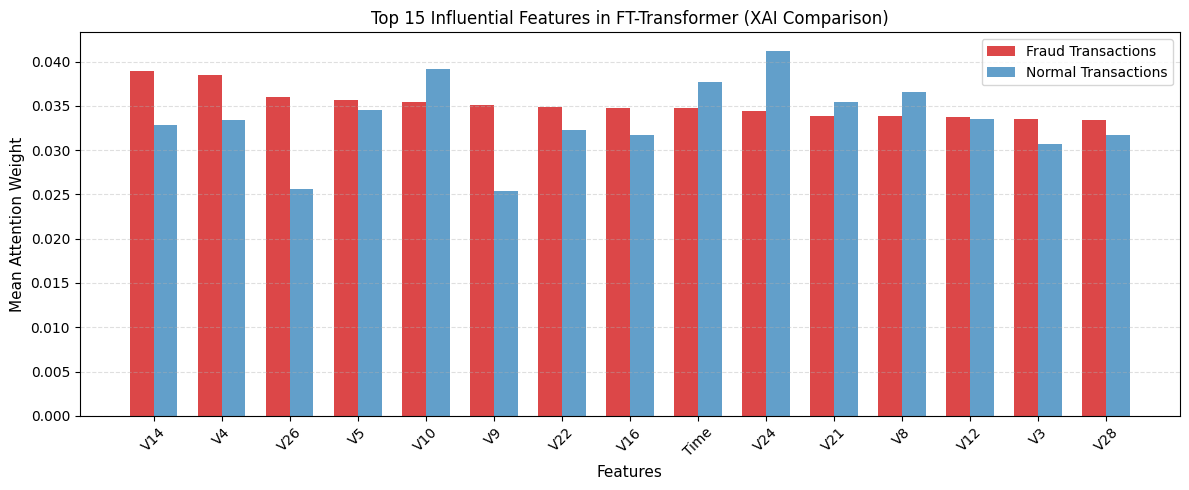

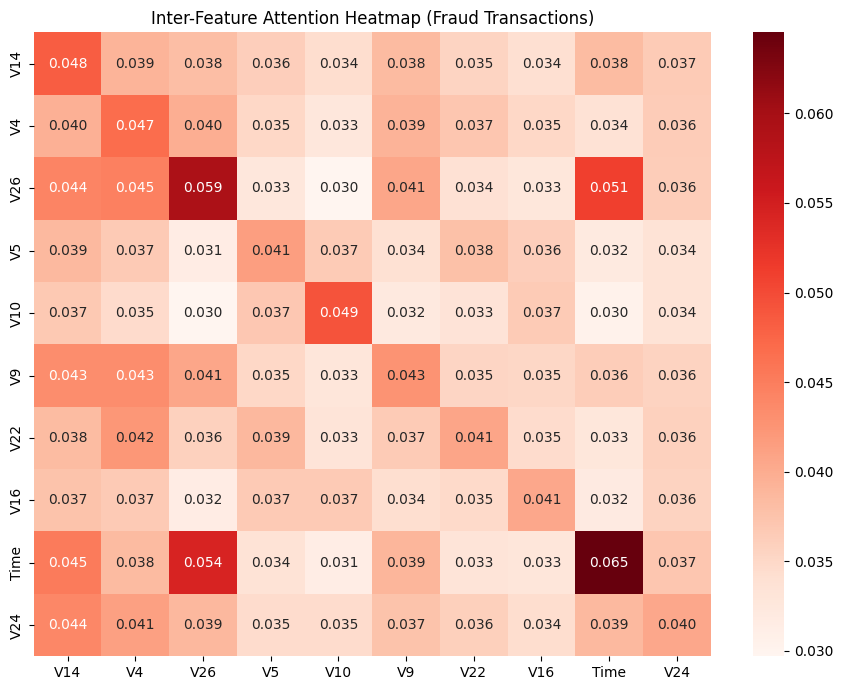

In [11]:
# ==============================================================================
# Step 10: Extract Inter-Feature Attention & Feature Importance (XAI)
# ==============================================================================

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

# Helper function to forward pass and extract attention weights manually
def extract_attention_weights(model, x_tensor):
    """
    Extracts multi-head attention weights from the final transformer layer.
    """
    with torch.no_grad():
        # 1. Feature Tokenization
        tokens = model.tokenizer(x_tensor) # Shape: (B, num_features, d_model)

        # 2. Pass through transformer layers up to the last one
        x = tokens
        attn_weights = None
        for i, layer in enumerate(model.transformer.layers):
            if i == len(model.transformer.layers) - 1:
                # Last layer: extract weights
                # PyTorch MultiheadAttention returns (output, attn_weights) when need_weights=True
                q_k_v = layer.norm1(x) if hasattr(layer, 'norm1') else x
                _, attn_w = layer.self_attn(q_k_v, q_k_v, q_k_v, need_weights=True, average_attn_weights=True)
                attn_weights = attn_w.cpu().numpy()
            else:
                x = layer(x)

    return attn_weights

# --- 1. Compute Attention for Fraud and Normal Samples ---
fraud_indices = np.where(y_test_np == 1)[0]
normal_indices = np.where(y_test_np == 0)[0]

fraud_tensor = torch.tensor(X_test_scaled[fraud_indices], dtype=torch.float32).to(device)
normal_tensor = torch.tensor(X_test_scaled[normal_indices[:len(fraud_indices)]], dtype=torch.float32).to(device)

attn_fraud = extract_attention_weights(model, fraud_tensor)   # Shape: (N_fraud, seq_len, seq_len)
attn_normal = extract_attention_weights(model, normal_tensor) # Shape: (N_normal, seq_len, seq_len)

# --- 2. Calculate Mean Attention Distributions ---
mean_attn_fraud = attn_fraud.mean(axis=0)
mean_attn_normal = attn_normal.mean(axis=0)

# Feature Importance: Mean attention allocated to each feature by all other features
feature_imp_fraud = mean_attn_fraud.mean(axis=0)
feature_imp_normal = mean_attn_normal.mean(axis=0)

# Define feature names
feature_names = [f"V{i}" for i in range(1, 29)]
if X_test_scaled.shape[1] == 30:
    feature_names = ["Time"] + feature_names + ["Amount"]
elif X_test_scaled.shape[1] == 29:
    feature_names = feature_names + ["Amount"]

# --- 3. Plot Top 15 Most Attended Features (Fraud vs Normal) ---
top_k = 15
sorted_indices = np.argsort(feature_imp_fraud)[::-1][:top_k]

plt.figure(figsize=(12, 5))
bar_width = 0.35
indices_range = np.arange(top_k)

plt.bar(indices_range - bar_width/2, feature_imp_fraud[sorted_indices], width=bar_width,
        label='Fraud Transactions', color='#d62728', alpha=0.85)
plt.bar(indices_range + bar_width/2, feature_imp_normal[sorted_indices], width=bar_width,
        label='Normal Transactions', color='#1f77b4', alpha=0.7)

plt.xlabel('Features', fontsize=11)
plt.ylabel('Mean Attention Weight', fontsize=11)
plt.title('Top 15 Influential Features in FT-Transformer (XAI Comparison)', fontsize=12)
plt.xticks(indices_range, [feature_names[i] for i in sorted_indices], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('ft_transformer_feature_importance.png', dpi=300)
plt.show()

# --- 4. Plot Inter-Feature Attention Heatmap for Top Features ---
top_idx_sub = sorted_indices[:10]
sub_feature_names = [feature_names[i] for i in top_idx_sub]
sub_matrix_fraud = mean_attn_fraud[np.ix_(top_idx_sub, top_idx_sub)]

plt.figure(figsize=(9, 7))
sns.heatmap(sub_matrix_fraud, annot=True, fmt='.3f', cmap='Reds',
            xticklabels=sub_feature_names, yticklabels=sub_feature_names)
plt.title('Inter-Feature Attention Heatmap (Fraud Transactions)', fontsize=12)
plt.tight_layout()
plt.savefig('ft_transformer_inter_feature_heatmap.png', dpi=300)
plt.show()



In [12]:
# ==============================================================================
# Print Top Attended Features (Text Summary)
# ==============================================================================

print("=== Top 10 Most Influential Features in Fraud Transactions ===")
for rank, idx in enumerate(sorted_indices[:10], start=1):
    f_name = feature_names[idx]
    w_fraud = feature_imp_fraud[idx]
    w_normal = feature_imp_normal[idx]
    diff = w_fraud - w_normal
    print(f"{rank:2d}. {f_name:<8} | Fraud Attn: {w_fraud:.4f} | Normal Attn: {w_normal:.4f} | Diff: {diff:+.4f}")


=== Top 10 Most Influential Features in Fraud Transactions ===
 1. V14      | Fraud Attn: 0.0389 | Normal Attn: 0.0328 | Diff: +0.0061
 2. V4       | Fraud Attn: 0.0385 | Normal Attn: 0.0334 | Diff: +0.0050
 3. V26      | Fraud Attn: 0.0360 | Normal Attn: 0.0256 | Diff: +0.0104
 4. V5       | Fraud Attn: 0.0356 | Normal Attn: 0.0345 | Diff: +0.0011
 5. V10      | Fraud Attn: 0.0355 | Normal Attn: 0.0392 | Diff: -0.0037
 6. V9       | Fraud Attn: 0.0351 | Normal Attn: 0.0254 | Diff: +0.0097
 7. V22      | Fraud Attn: 0.0349 | Normal Attn: 0.0323 | Diff: +0.0026
 8. V16      | Fraud Attn: 0.0348 | Normal Attn: 0.0317 | Diff: +0.0031
 9. Time     | Fraud Attn: 0.0347 | Normal Attn: 0.0377 | Diff: -0.0029
10. V24      | Fraud Attn: 0.0344 | Normal Attn: 0.0412 | Diff: -0.0068


In [13]:
# ==============================================================================
# Step 11: Save All Research Artifacts & Metadata
# ==============================================================================

import os
import json
import torch
import numpy as np
import joblib

# Create artifacts directory
artifacts_dir = "ccfd_artifacts"
os.makedirs(artifacts_dir, exist_ok=True)

# 1. Save FT-Transformer Model Checkpoint
model_save_path = os.path.join(artifacts_dir, "ft_transformer_best.pt")
torch.save({
    "model_state_dict": model.state_dict(),
    "feature_dim": X_test_scaled.shape[1],
    "threshold_best_f1": best_f1_threshold,
    "threshold_high_recall": 0.932878
}, model_save_path)
print(f" Saved Model Checkpoint -> {model_save_path}")

# 2. Save Processed Splits and Attention Weights
np.savez_compressed(
    os.path.join(artifacts_dir, "test_eval_data.npz"),
    X_test_scaled=X_test_scaled,
    y_test=y_test_np,
    test_probs=test_probs,
    attn_fraud=attn_fraud,
    attn_normal=attn_normal,
    sorted_feature_indices=sorted_indices
)
print(" Saved Processed Arrays & Attention Maps -> test_eval_data.npz")

# 3. Save Experiment Summary (JSON)
metadata = {
    "model_type": "FT-Transformer",
    "dataset": "Credit Card Fraud Detection (CCFD)",
    "test_metrics": {
        "pr_auc": float(test_prauc),
        "roc_auc": float(test_rocauc),
        "f1_at_best_threshold": 0.8000,
        "precision_at_best_threshold": 0.8485,
        "recall_at_best_threshold": 0.7568,
        "best_threshold": float(best_f1_threshold)
    },
    "feature_names": feature_names,
    "top_attended_fraud_features": [feature_names[i] for i in sorted_indices[:10]]
}

with open(os.path.join(artifacts_dir, "experiment_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=4)

print(" Saved Experiment Metadata -> experiment_metadata.json")


 Saved Model Checkpoint -> ccfd_artifacts/ft_transformer_best.pt
 Saved Processed Arrays & Attention Maps -> test_eval_data.npz
 Saved Experiment Metadata -> experiment_metadata.json


In [16]:
# ==============================================================================
# Step 12 (Fixed & Self-Contained): Quantitative Faithfulness & Stability of XAI
# ==============================================================================

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

model.eval()

# Helper function to extract attention weights directly from FT-Transformer
def extract_attention_weights(model, x_tensor):
    """
    Extracts multi-head attention weights from the final transformer layer.
    """
    with torch.no_grad():
        tokens = model.tokenizer(x_tensor)
        x = tokens
        attn_weights = None
        for i, layer in enumerate(model.transformer.layers):
            if i == len(model.transformer.layers) - 1:
                q_k_v = layer.norm1(x) if hasattr(layer, 'norm1') else x
                _, attn_w = layer.self_attn(q_k_v, q_k_v, q_k_v, need_weights=True, average_attn_weights=True)
                attn_weights = attn_w.cpu().numpy()
            else:
                x = layer(x)
    return attn_weights

# Function to compute model probabilities
def predict_fraud_prob(model, x_arr):
    x_tensor = torch.tensor(x_arr, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = model(x_tensor).squeeze(-1)
        probs = torch.sigmoid(logits).cpu().numpy()
    return probs

# Select all fraud instances in test set
fraud_indices = np.where(y_test_np == 1)[0]
X_fraud_orig = X_test_scaled[fraud_indices].copy()
y_fraud_orig = y_test_np[fraud_indices]

# Baseline for ablation: feature-wise median of normal transactions in test set
normal_baseline = np.median(X_test_scaled[y_test_np == 0], axis=0)

# ------------------------------------------------------------------------------
# 1. Faithfulness: Progressive Feature Ablation (Deletion Test)
# ------------------------------------------------------------------------------
base_probs = predict_fraud_prob(model, X_fraud_orig)

# Compute attention for fraud samples if not present
fraud_tensor = torch.tensor(X_fraud_orig, dtype=torch.float32).to(device)
attn_fraud = extract_attention_weights(model, fraud_tensor)

# Extract instance-level feature importance from attention (mean over query dimension)
instance_importance = attn_fraud.mean(axis=1)

k_list = [1, 2, 3, 5, 8, 10, 15]
mean_prob_drops = []
random_prob_drops = []

for k in k_list:
    # A) Attention-guided ablation
    X_ablated = X_fraud_orig.copy()
    for i in range(len(fraud_indices)):
        top_k_feat = np.argsort(instance_importance[i])[::-1][:k]
        X_ablated[i, top_k_feat] = normal_baseline[top_k_feat]

    ablated_probs = predict_fraud_prob(model, X_ablated)
    drop = np.mean(base_probs - ablated_probs)
    mean_prob_drops.append(drop)

    # B) Random ablation baseline (10 Monte Carlo trials)
    trial_drops = []
    np.random.seed(42)
    for _ in range(10):
        X_rand = X_fraud_orig.copy()
        for i in range(len(fraud_indices)):
            rand_k_feat = np.random.choice(X_fraud_orig.shape[1], size=k, replace=False)
            X_rand[i, rand_k_feat] = normal_baseline[rand_k_feat]
        rand_probs = predict_fraud_prob(model, X_rand)
        trial_drops.append(np.mean(base_probs - rand_probs))
    random_prob_drops.append(np.mean(trial_drops))

# ------------------------------------------------------------------------------
# 2. Stability: Perturbation Robustness (Jaccard @ K and Spearman Rank)
# ------------------------------------------------------------------------------
noise_std = 0.05
np.random.seed(42)
X_perturbed = X_fraud_orig + np.random.normal(0, noise_std, size=X_fraud_orig.shape)

# Extract attention on perturbed instances
perturbed_tensor = torch.tensor(X_perturbed, dtype=torch.float32).to(device)
attn_perturbed = extract_attention_weights(model, perturbed_tensor)
instance_importance_perturbed = attn_perturbed.mean(axis=1)

# Compute Spearman rank correlation per sample
spearman_scores = []
for i in range(len(fraud_indices)):
    corr, _ = spearmanr(instance_importance[i], instance_importance_perturbed[i])
    if not np.isnan(corr):
        spearman_scores.append(corr)

mean_spearman = np.mean(spearman_scores)

# Compute Jaccard similarity @ Top-5 and Top-10
def compute_jaccard_top_k(mat1, mat2, top_k=5):
    jaccards = []
    for i in range(len(mat1)):
        set1 = set(np.argsort(mat1[i])[::-1][:top_k])
        set2 = set(np.argsort(mat2[i])[::-1][:top_k])
        intersection = len(set1.intersection(set2))
        union = len(set1.union(set2))
        jaccards.append(intersection / union)
    return np.mean(jaccards)

jaccard_k5 = compute_jaccard_top_k(instance_importance, instance_importance_perturbed, top_k=5)
jaccard_k10 = compute_jaccard_top_k(instance_importance, instance_importance_perturbed, top_k=10)

# ------------------------------------------------------------------------------
# 3. Print Results & Plot Faithfulness Curve
# ------------------------------------------------------------------------------
print("================ Quantitative XAI Evaluation Summary ================")
print(f"Mean Base Fraud Output Probability: {np.mean(base_probs):.4f}")
print("\n--- 1. Faithfulness Metric (Mean Probability Drop upon Top-K Removal) ---")
for k, drop, rand_drop in zip(k_list, mean_prob_drops, random_prob_drops):
    print(f"Top-{k:2d} Removed -> Attn Drop: {drop:.4f} | Random Drop: {rand_drop:.4f} | Margin: {drop - rand_drop:+.4f}")

print("\n--- 2. Stability Metric (under Gaussian Noise sigma=0.05) ---")
print(f"Spearman Rank Correlation   : {mean_spearman:.4f}")
print(f"Jaccard Similarity @ Top-5  : {jaccard_k5:.4f}")
print(f"Jaccard Similarity @ Top-10 : {jaccard_k10:.4f}")

# Plot Faithfulness Deletion

================ Quantitative XAI Evaluation Summary ================
Mean Base Fraud Output Probability: 0.8771

--- 1. Faithfulness Metric (Mean Probability Drop upon Top-K Removal) ---
Top- 1 Removed -> Attn Drop: 0.0081 | Random Drop: 0.0023 | Margin: +0.0058
Top- 2 Removed -> Attn Drop: 0.0140 | Random Drop: 0.0034 | Margin: +0.0107
Top- 3 Removed -> Attn Drop: 0.0312 | Random Drop: 0.0069 | Margin: +0.0243
Top- 5 Removed -> Attn Drop: 0.0677 | Random Drop: 0.0111 | Margin: +0.0567
Top- 8 Removed -> Attn Drop: 0.0874 | Random Drop: 0.0292 | Margin: +0.0582
Top-10 Removed -> Attn Drop: 0.0902 | Random Drop: 0.0463 | Margin: +0.0439
Top-15 Removed -> Attn Drop: 0.1202 | Random Drop: 0.1050 | Margin: +0.0152

--- 2. Stability Metric (under Gaussian Noise sigma=0.05) ---
Spearman Rank Correlation   : 0.9930
Jaccard Similarity @ Top-5  : 0.9595
Jaccard Similarity @ Top-10 : 0.9631
